In [21]:
import scanpy as sc

In [22]:
sc.settings.verbosity = 3  
sc.set_figure_params(dpi=80, facecolor='white')

loading data

In [23]:
adata = sc.read_10x_h5('pbmc_10x.h5')
adata.var_names_make_unique()
print(adata)

reading pbmc_10x.h5
 (0:00:00)
AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids', 'feature_types', 'genome'


Quality Control(QC)

In [24]:
adata.var['mt'] = adata.var_names.str.startswith('MT-')
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)

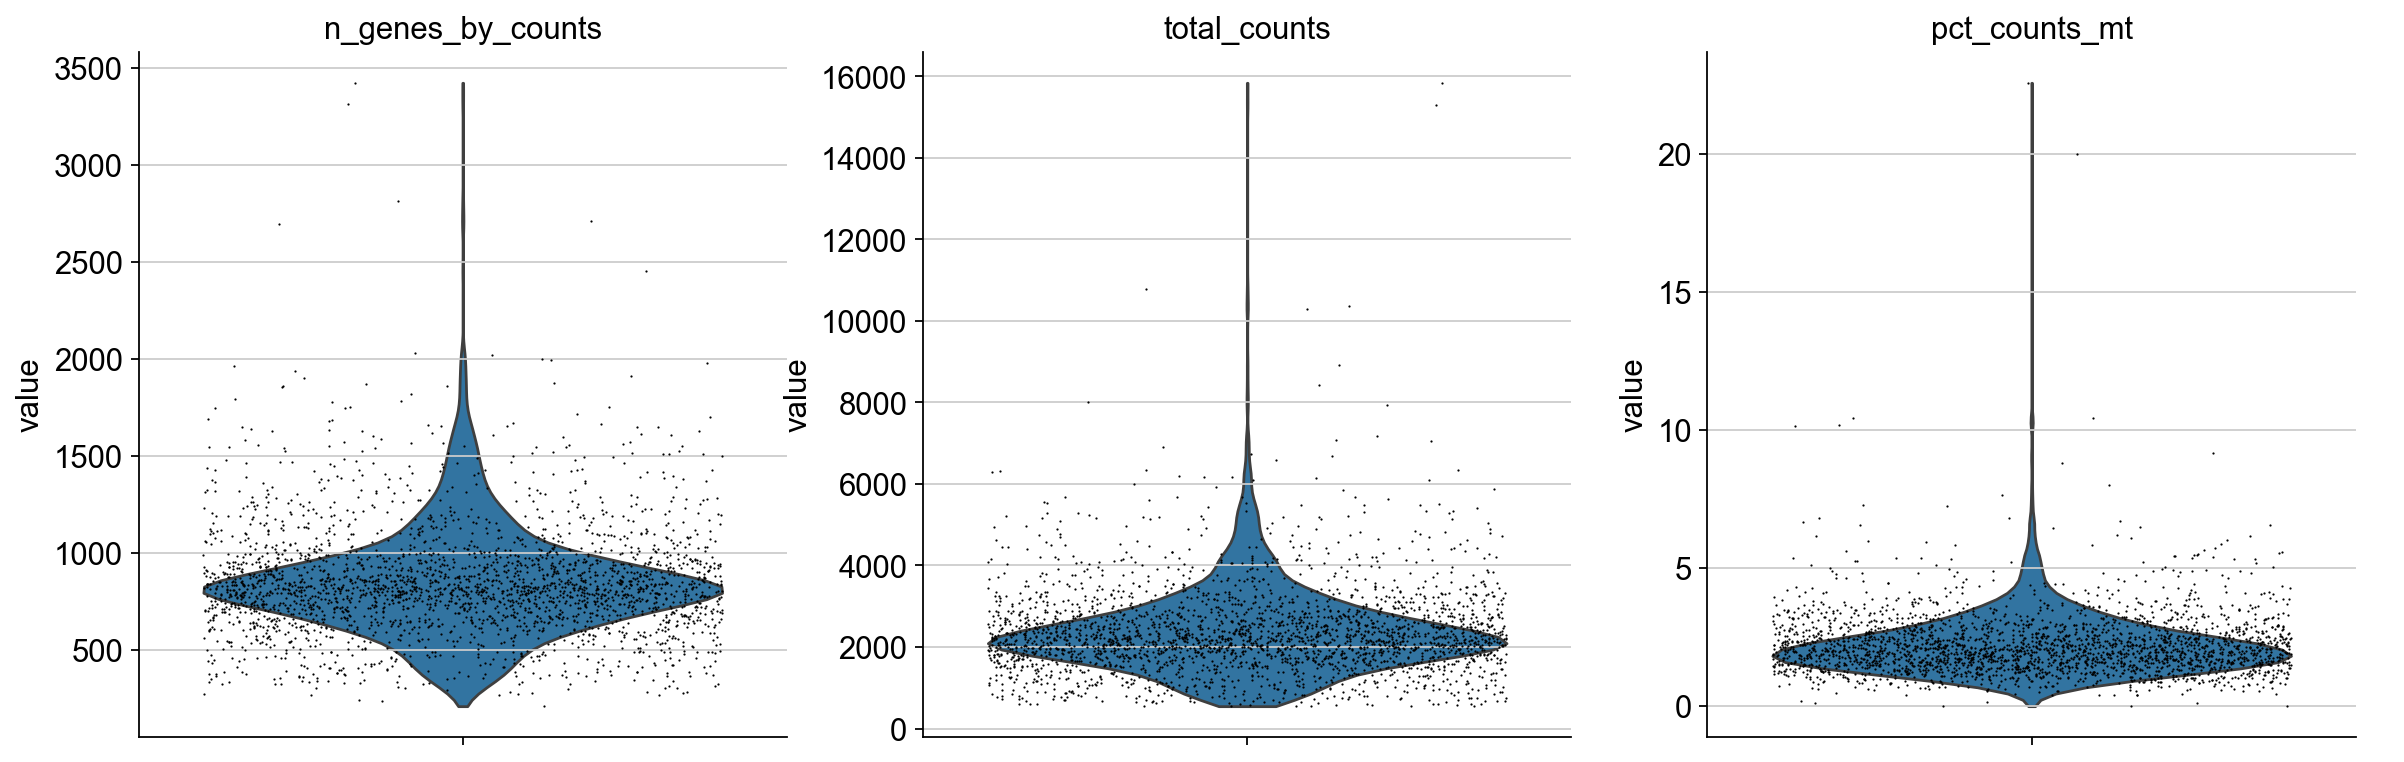

In [25]:
sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'],jitter=0.4, multi_panel=True)

In [26]:
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[(adata.obs.n_genes_by_counts > 200) & 
              (adata.obs.n_genes_by_counts < 2500) & 
              (adata.obs.pct_counts_mt < 5), :].copy()

filtered out 19024 genes that are detected in less than 3 cells


In [27]:
print(adata)

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'


Normalization

In [28]:
adata.raw = adata

sc.pp.normalize_total(adata, target_sum=1e4)


sc.pp.log1p(adata)


normalizing counts per cell
    finished (0:00:00)


Highly Variable Genes - HVGs

extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


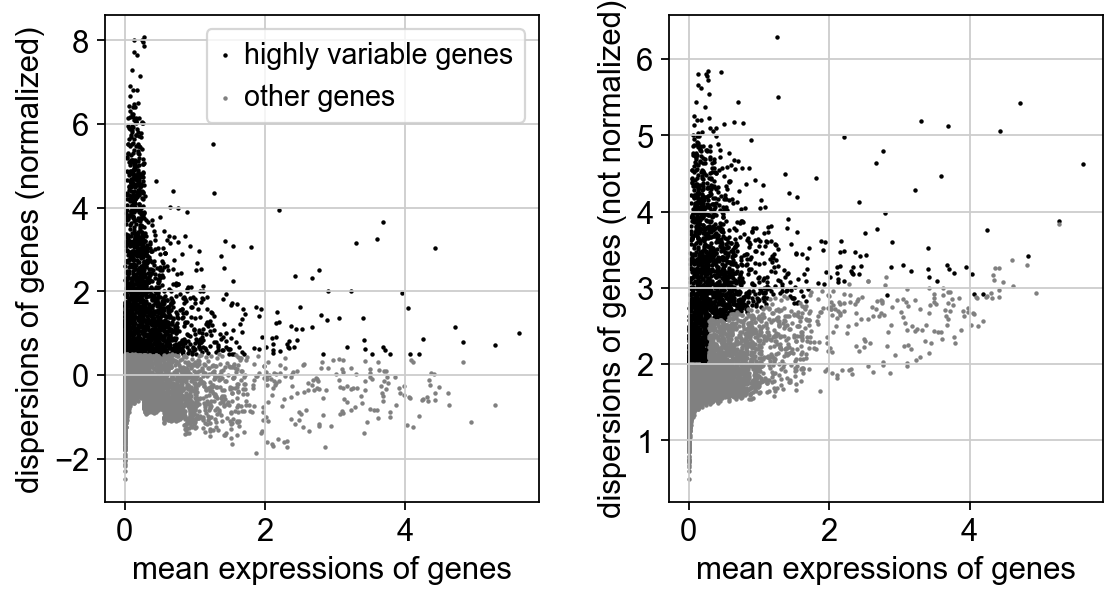

In [29]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5, n_top_genes=2000)


sc.pl.highly_variable_genes(adata)

Scaling data

In [30]:
sc.pp.scale(adata, max_value=10)

c:\Program Files\Python311\Lib\functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


PCA

computing PCA
    with n_comps=50
    finished (0:00:01)


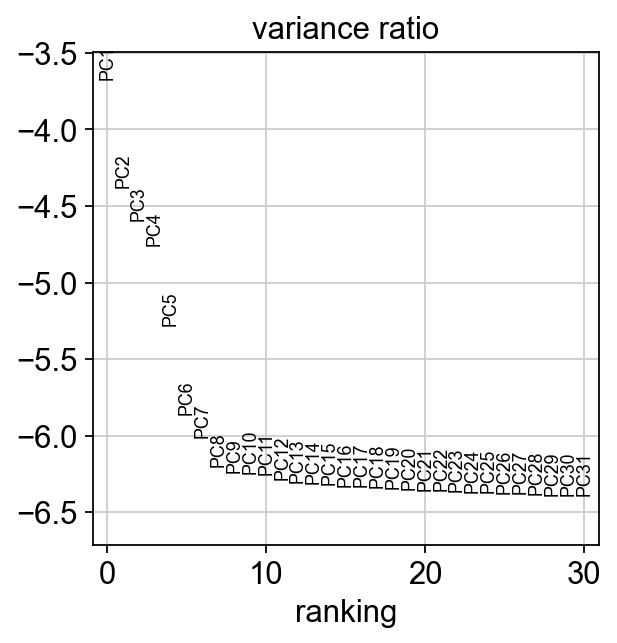

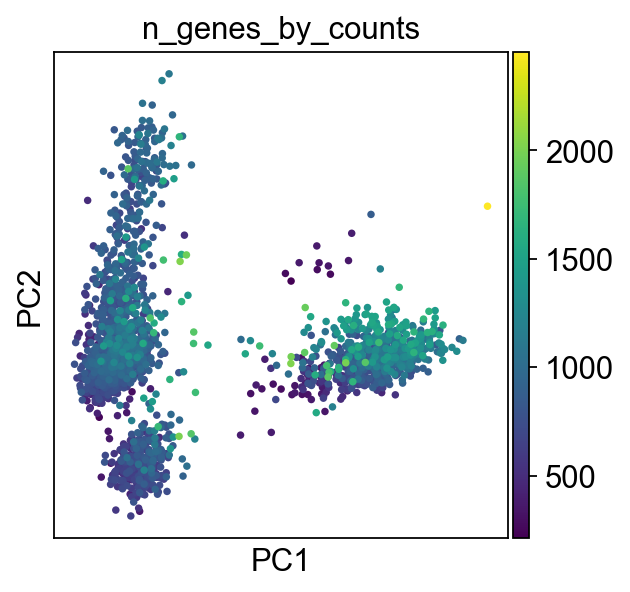

In [31]:

sc.tl.pca(adata, svd_solver='arpack')


sc.pl.pca_variance_ratio(adata, n_pcs=30, log=True)


sc.pl.pca(adata, color='n_genes_by_counts')

clustering

In [32]:
import igraph as ig
import leidenalg

In [33]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=10)


sc.tl.leiden(adata, resolution=0.5)

computing neighbors
    using 'X_pca' with n_pcs = 10
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
running Leiden clustering
    finished: found 8 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


UMAP

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:02)


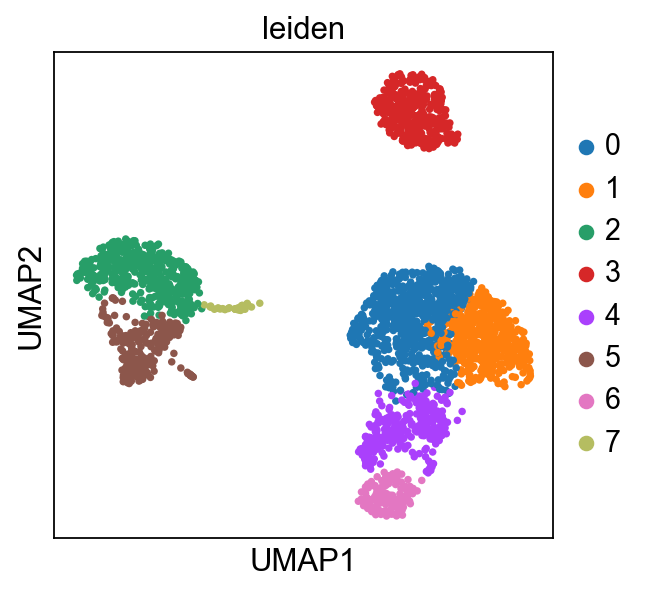

In [34]:
sc.tl.umap(adata)


sc.pl.umap(adata, color=['leiden'])

Finding Marker Genes

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:00)


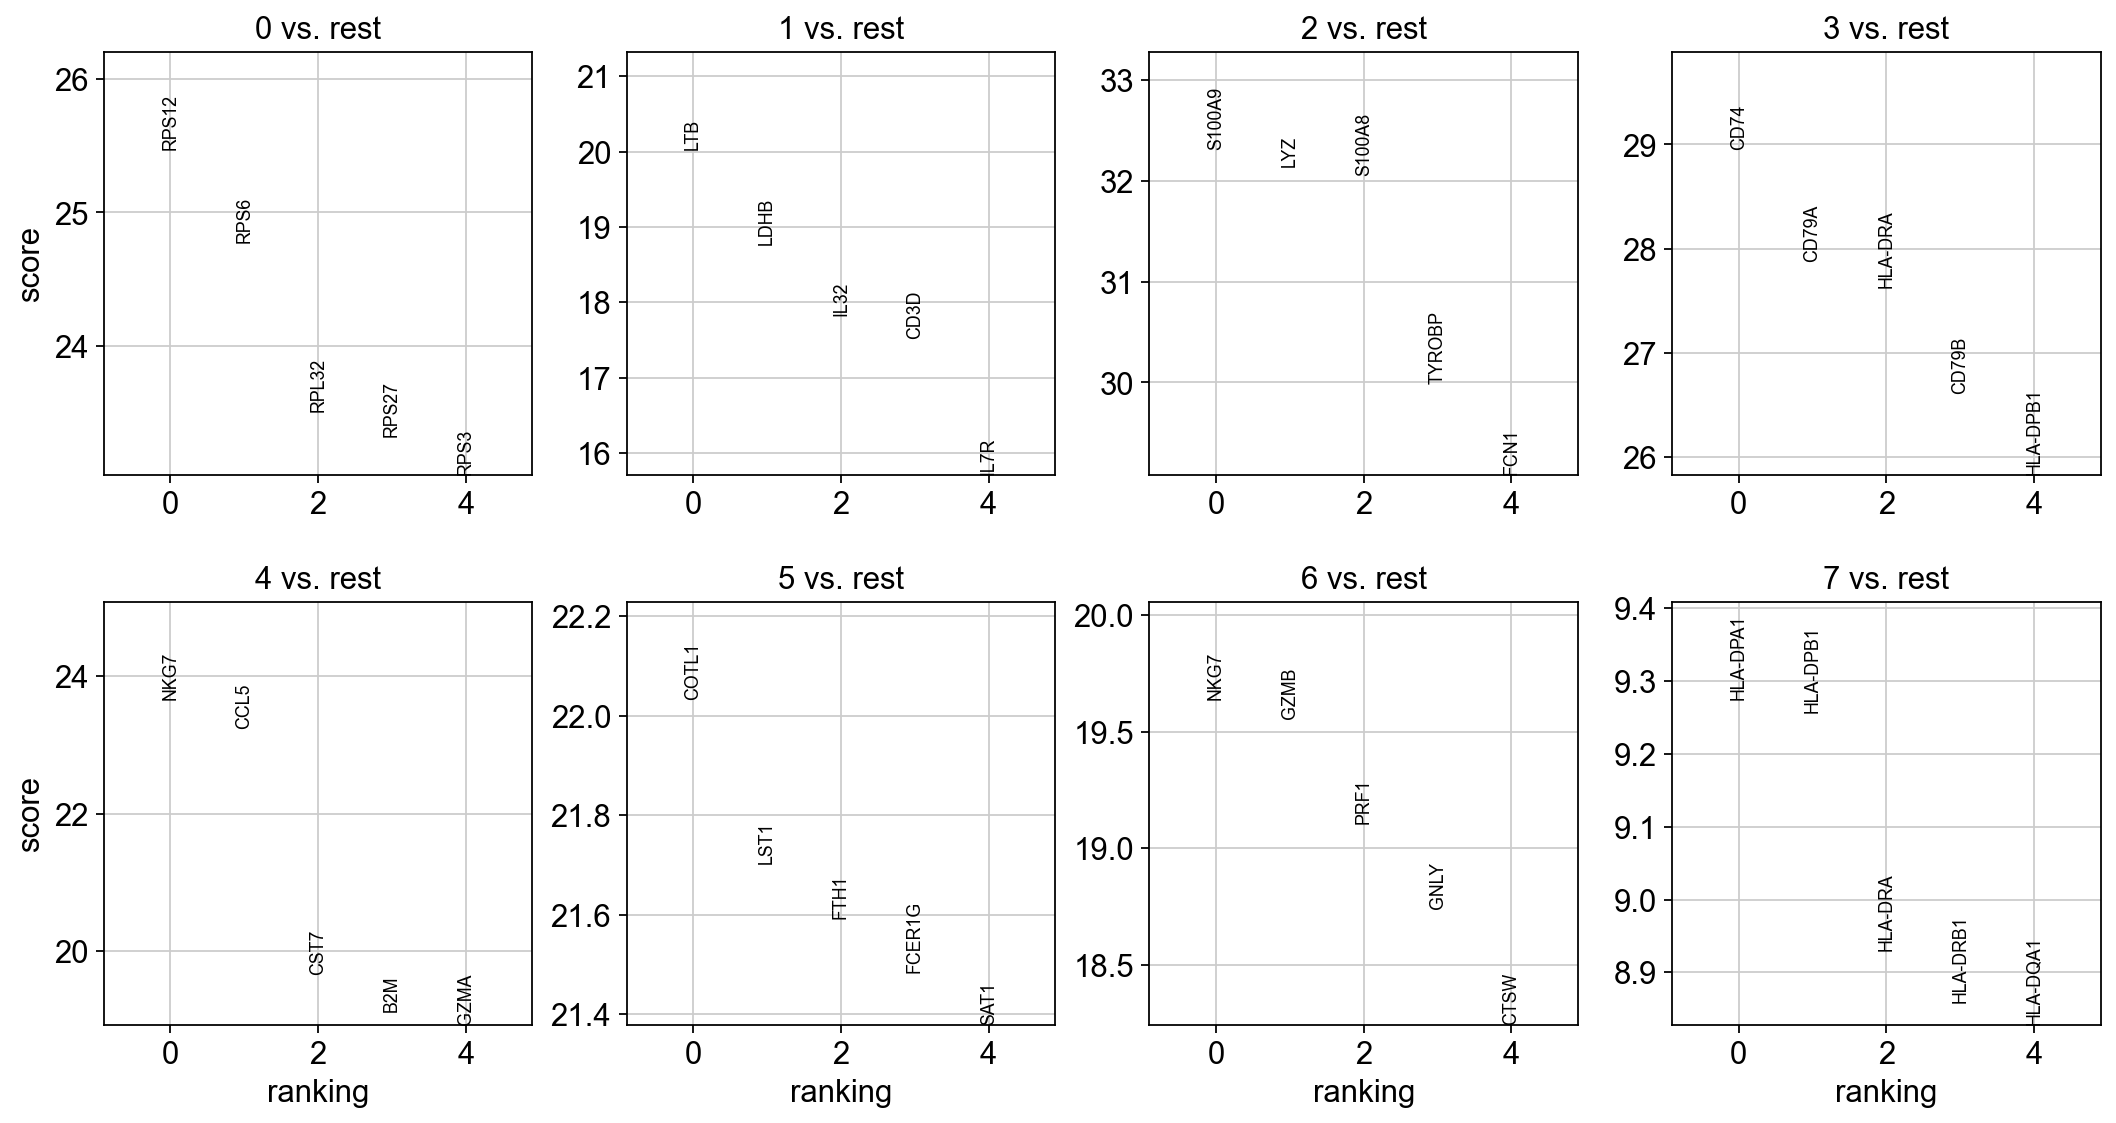

In [35]:

sc.tl.rank_genes_groups(adata, 'leiden', method='wilcoxon')


sc.pl.rank_genes_groups(adata, n_genes=5, sharey=False)

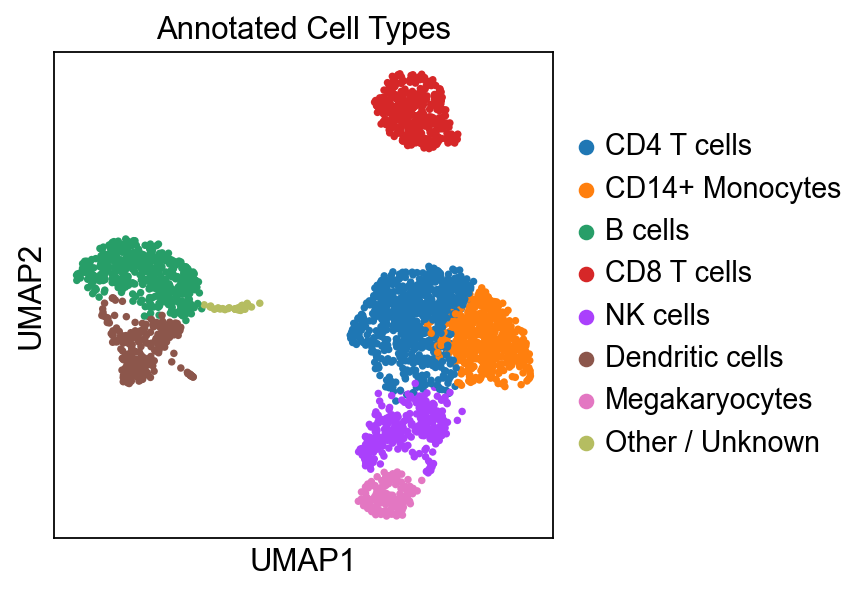

In [36]:
import pandas as pd


cluster_names = {
    '0': 'CD4 T cells',
    '1': 'CD14+ Monocytes',
    '2': 'B cells',
    '3': 'CD8 T cells',
    '4': 'NK cells',
    '5': 'Dendritic cells',
    '6': 'Megakaryocytes',
    '7': 'Other / Unknown'
}


adata.obs['leiden'] = adata.obs['leiden'].map(cluster_names).astype('category')

#  رسم مجدد UMAP با نام‌های جدید سلولی
sc.pl.umap(adata, color='leiden', legend_loc='right margin', title='Annotated Cell Types')

Feature plot

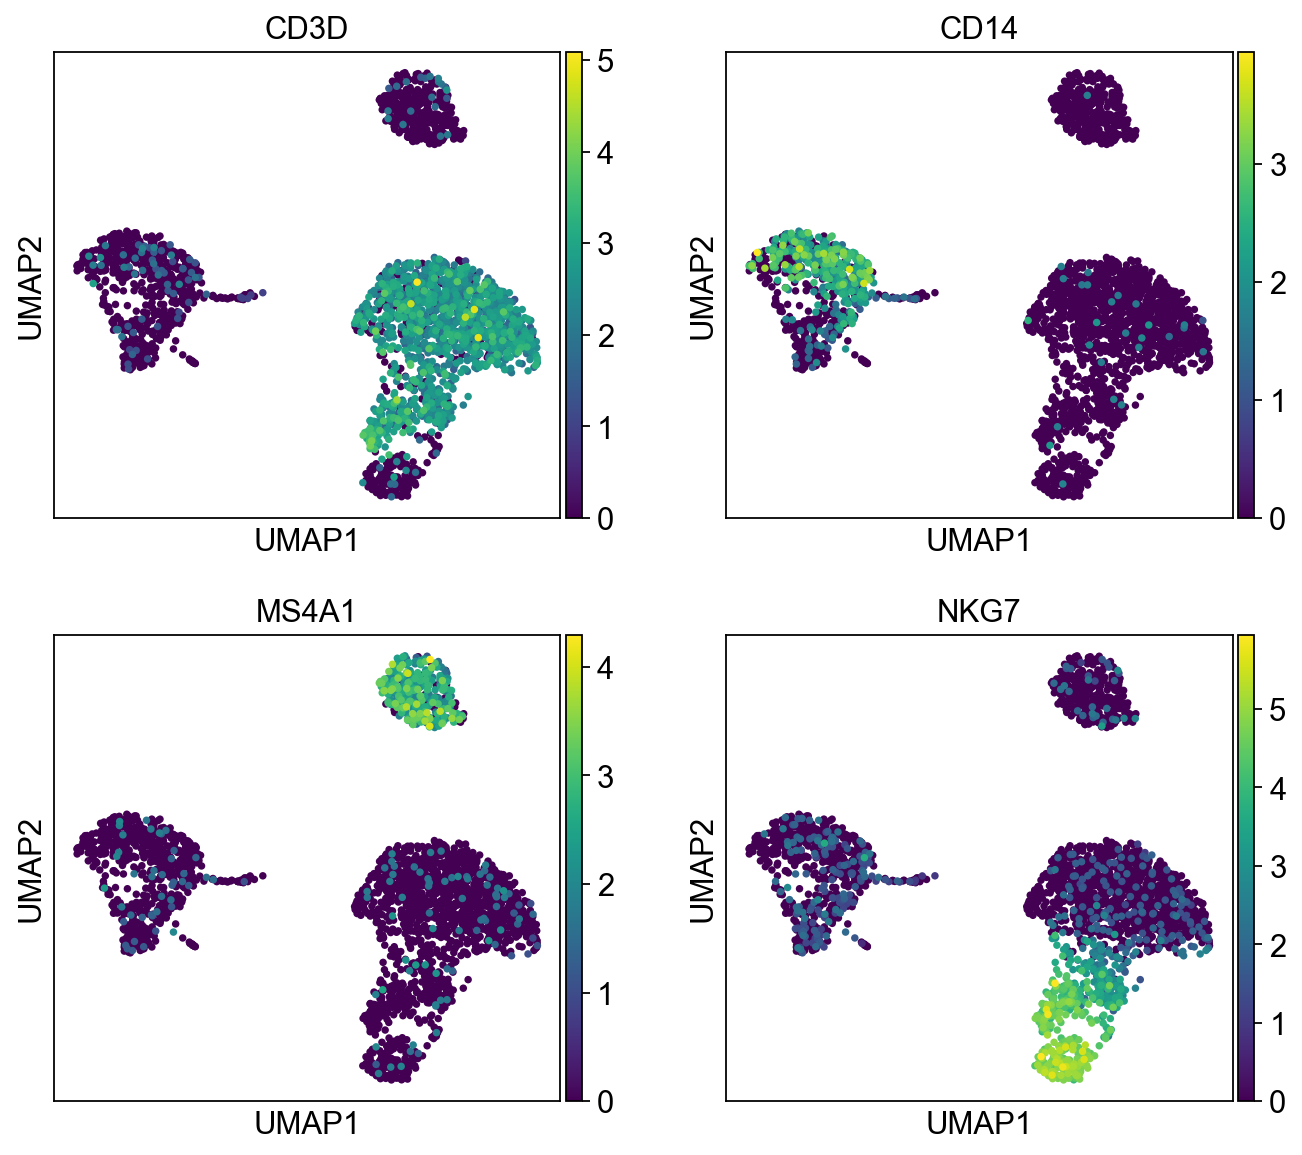

In [37]:

sc.pl.umap(
    adata, 
    color=['CD3D', 'CD14', 'MS4A1', 'NKG7'], 
    color_map='viridis',  
    ncols=2               
)

Heatmap 

    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_leiden']`


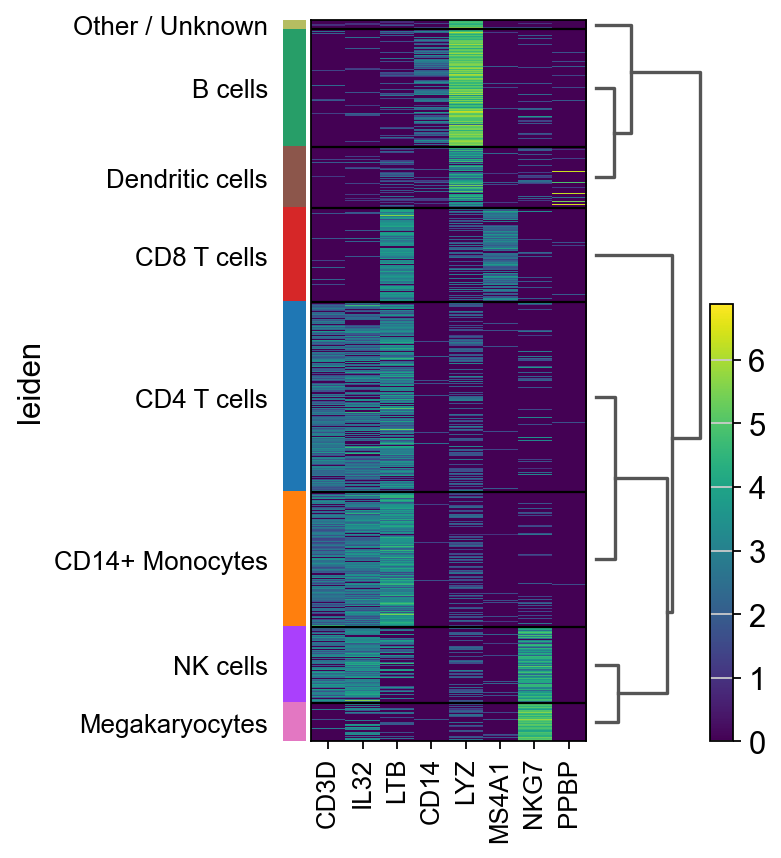

In [39]:
marker_genes = ['CD3D', 'IL32', 'LTB', 'CD14', 'LYZ', 'MS4A1', 'NKG7', 'PPBP']
sc.pl.heatmap(adata, marker_genes, groupby='leiden', dendrogram=True, cmap='viridis')